# 03 — Results

Every result of the study, read from saved files only. This notebook never runs the experiment
and never opens the test set: `python -m fraudstudy.experiments` wrote the cell files,
`python -m fraudstudy.evaluation --test` wrote `test_results.json` (the one opening of the test
set) and `--stats` wrote `stats.json`. Each section below says what it shows and how to read it.
Figures are saved to `artifacts/figures/`.

**Setup.** Imports, the data source and the saved results. `SOURCE = "sample"` reads the trial run
on the fake data in `artifacts/sample/` instead; its numbers mean nothing and are never committed.
`models` lists the models that have finished cells, so the notebook also works while some are
still running.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from fraudstudy.evaluation import load_cells
from fraudstudy.experiments import MODELS, TECHNIQUES, artifacts_dir

SOURCE = "raw"  # "raw" = the real results, "sample" = the fake copy in artifacts/sample/
METRICS_DIR = artifacts_dir(SOURCE) / "metrics"
FIGURES_DIR = artifacts_dir(SOURCE) / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
LABELS = {"baseline": "A baseline", "ros": "B ROS", "rus": "C RUS", "smote": "D SMOTE",
          "smote_rus": "E SMOTE+RUS", "class_weight": "F class weight"}


def read_json(name: str) -> dict | None:
    """One saved results file from METRICS_DIR, or None if it does not exist yet."""
    path = METRICS_DIR / name
    return json.loads(path.read_text()) if path.is_file() else None


cells = load_cells(SOURCE)  # every finished cell, from experiments.py
test_results = read_json("test_results.json")  # from evaluation.py --test
stats = read_json("stats.json")  # from evaluation.py --stats
eda_summary = read_json("eda_summary.json")  # from notebooks/01_eda.ipynb
models = [m for m in MODELS if any(cell["model"] == m for cell in cells.values())]
print(f"{len(cells)} cells loaded from {METRICS_DIR}; models: {', '.join(models)}")
if test_results is None:
    print("test_results.json is missing: run python -m fraudstudy.evaluation --test first.")

18 cells loaded from C:\Users\Shaurya Agarwal\Documents\ML project Credit Card\artifacts\metrics; models: logreg, random_forest, lightgbm


## 1. The data in numbers
How many payments, how many frauds, and how the 70/30 split divides them. The numbers come from
the EDA summary; when it is missing (as on the fake sample), they are rebuilt from one cell:
its training class counts plus the four counts of its test confusion matrix. The rebuilt
numbers are after duplicate removal, so they can be a little smaller than the EDA ones.

In [2]:
if eda_summary is not None:
    rows, frauds = eda_summary["rows"], eda_summary["frauds"]
    train_rows, test_rows = eda_summary["train_rows"], eda_summary["test_rows"]
else:
    name = next(iter(cells))  # any cell: they all share the same split
    before, test = cells[name]["train_counts_before"], test_results[name]["test"]
    train_rows = before["legit"] + before["fraud"]
    test_rows = test["tp"] + test["fp"] + test["tn"] + test["fn"]
    rows = train_rows + test_rows
    frauds = before["fraud"] + test["tp"] + test["fn"]  # frauds = caught + missed in the test
fraud_rate = frauds / rows
print(f"payments:   {rows:,}")
print(f"frauds:     {frauds:,}")
print(f"fraud rate: {fraud_rate:.4%} (1 fraud for every {round((rows - frauds) / frauds)} legit)")
print(f"training:   {train_rows:,} rows    test: {test_rows:,} rows")

payments:   284,807
frauds:     492
fraud rate: 0.1727% (1 fraud for every 578 legit)
training:   198,608 rows    test: 85,118 rows


## 2. What each technique does to the training data
One panel per model: the bars are the training class counts the model was fitted on after the
technique (at the ratio the search picked), the dashed lines the counts before. The y-axis is
logarithmic, otherwise the fraud bars would be invisible. Oversampling (B, D) raises the fraud
bar, undersampling (C) lowers the legit bar, E does both, and the baseline (A) and class
weighting (F) leave the rows unchanged (F changes the weights instead). These are counts of
training rows only; validation and test rows are never resampled.

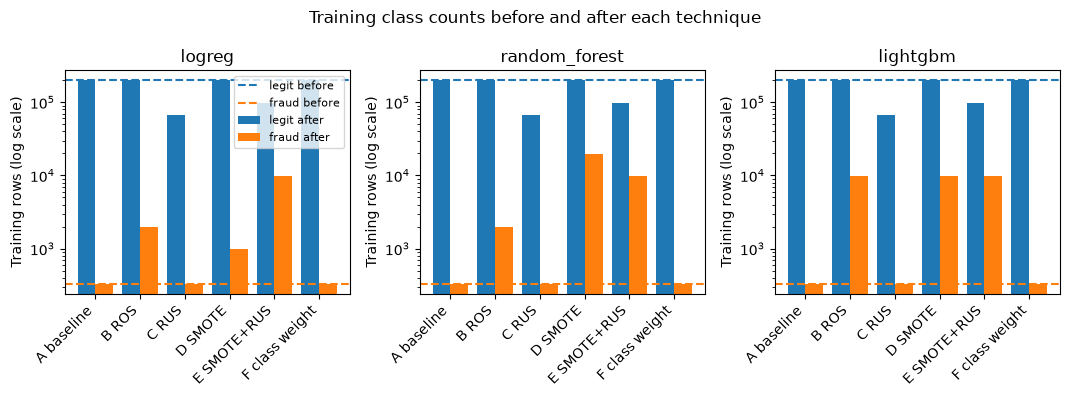

In [3]:
fig, axes = plt.subplots(1, len(models), figsize=(3.6 * len(models), 4), squeeze=False)
for ax, model in zip(axes[0], models, strict=True):
    names = [t for t in TECHNIQUES if f"{model}__{t}" in cells]
    after = [cells[f"{model}__{t}"]["train_counts_after"] for t in names]
    before = cells[f"{model}__{names[0]}"]["train_counts_before"]
    x = np.arange(len(names))
    ax.bar(x - 0.2, [a["legit"] for a in after], 0.4, label="legit after")
    ax.bar(x + 0.2, [a["fraud"] for a in after], 0.4, label="fraud after")
    ax.axhline(before["legit"], color="C0", linestyle="--", label="legit before")
    ax.axhline(before["fraud"], color="C1", linestyle="--", label="fraud before")
    ax.set_xticks(x, [LABELS[t] for t in names], rotation=45, ha="right")
    ax.set(yscale="log", title=model, ylabel="Training rows (log scale)")
axes[0][0].legend(fontsize=8)
fig.suptitle("Training class counts before and after each technique")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "training_counts.png", dpi=150)
plt.show()

## 3. Cross-validation results (training rows only)
One row per cell, best first: the mean and spread of PR-AUC over the repeated-CV folds, the
ratio(s) the search chose, and the F1 threshold chosen on out-of-fold scores. For a sampler the
ratio is "frauds = r x legit after resampling"; for class weighting it is the fraud weight w and
the ratio it matches (r = w x frauds / legit).

The cell at the top is the **headline cell**. It is chosen here, from training-only
cross-validation scores, so the test set plays no part in choosing it.

In [4]:
def chosen_ratios(cell: dict) -> str:
    """The resampling ratio(s) or fraud weight the search picked for one cell, as short text."""
    counts = cell["train_counts_before"]
    base = counts["fraud"] / counts["legit"]
    parts = []
    for name, value in cell["best_params"].items():
        if name.endswith("sampling_strategy"):  # e.g. smote__sampling_strategy
            parts.append(f"{name.split('__')[0]} {value}")
        elif name == "model__scale_pos_weight":
            parts.append(f"fraud weight {value:.1f} (r = {value * base:.3g})")
        elif name == "model__class_weight" and value == "balanced":
            parts.append("balanced")
        elif name == "model__class_weight":
            weight = value["1"]  # JSON turned the class key 1 into the text "1"
            parts.append(f"fraud weight {weight:.1f} (r = {weight * base:.3g})")
    return ", ".join(parts) or "-"


cv_table = pd.DataFrame([{
    "model": cell["model"], "technique": LABELS[cell["technique"]],
    "CV PR-AUC mean": cell["cv_pr_auc_mean"], "CV PR-AUC std": cell["cv_pr_auc_std"],
    "chosen ratio(s)": chosen_ratios(cell), "F1 threshold": cell["threshold_f1"],
} for cell in cells.values()])
cv_table = cv_table.sort_values("CV PR-AUC mean", ascending=False, ignore_index=True)
headline = max(cells, key=lambda name: cells[name]["cv_pr_auc_mean"])
print(f"headline cell (highest CV PR-AUC): {headline}")
cv_table.round(4)

headline cell (highest CV PR-AUC): lightgbm__smote


,model,technique,CV PR-AUC mean,CV PR-AUC std,chosen ratio(s),F1 threshold
0,lightgbm,D SMOTE,0.8643,0.0356,smote 0.05,0.9547
1,lightgbm,B ROS,0.8626,0.0327,ros 0.05,0.2567
2,lightgbm,E SMOTE+RUS,0.8566,0.0337,"smote 0.05, rus 0.1",0.9882
3,random_forest,D SMOTE,0.8548,0.0343,smote 0.1,0.5250
4,random_forest,A baseline,0.8471,0.0347,-,0.4702
5,random_forest,F class weight,0.8468,0.0297,fraud weight 30.0 (r = 0.05),0.5144
6,random_forest,B ROS,0.8460,0.0326,ros 0.01,0.6650
7,lightgbm,A baseline,0.8441,0.0391,-,0.0189
8,lightgbm,C RUS,0.8441,0.0339,rus 0.005,0.8370
9,random_forest,E SMOTE+RUS,0.8406,0.0327,"smote 0.05, rus 0.1",0.6990


## 4. Test results
Every cell scored once on the test set it never saw, at the F1 threshold it chose on training
data. PR-AUC is the main metric; its 95% confidence interval comes from a stratified bootstrap
of the test rows, so overlapping intervals mean the test set cannot tell those cells apart.
ROC-AUC uses the scores only; precision, recall, F1 and F2 count the flagged payments at the
threshold.

**Accuracy is shown only to prove that it is useless here:** it is close to 99.9% for every cell,
because almost every payment is legit, and it would be about as high for a model that never
flags anything.

In [5]:
rows_test = []
for model in models:
    for technique in TECHNIQUES:
        result = test_results.get(f"{model}__{technique}")
        if result is None:
            continue
        test, (low, high) = result["test"], result["pr_auc_ci"]
        rows_test.append({"model": model, "technique": LABELS[technique],
                          "test PR-AUC": test["pr_auc"], "95% CI": f"[{low:.3f}, {high:.3f}]",
                          "ROC-AUC": test["roc_auc"], "precision": test["precision"],
                          "recall": test["recall"], "F1": test["f1"], "F2": test["f2"],
                          "accuracy": test["accuracy"]})
test_table = pd.DataFrame(rows_test)
test_table.round(4)

,model,technique,test PR-AUC,95% CI,ROC-AUC,precision,recall,F1,F2,accuracy
0,logreg,A baseline,0.7149,"[0.633, 0.785]",0.9634,0.7941,0.7606,0.7770,0.7670,0.9993
1,logreg,B ROS,0.7179,"[0.633, 0.790]",0.9638,0.8045,0.7535,0.7782,0.7632,0.9993
2,logreg,C RUS,0.7191,"[0.635, 0.790]",0.9644,0.7985,0.7535,0.7754,0.7621,0.9993
3,logreg,D SMOTE,0.7214,"[0.637, 0.793]",0.9620,0.8060,0.7606,0.7826,0.7692,0.9993
4,logreg,E SMOTE+RUS,0.6971,"[0.607, 0.773]",0.9621,0.8060,0.7606,0.7826,0.7692,0.9993
5,logreg,F class weight,0.7214,"[0.638, 0.791]",0.9638,0.8045,0.7535,0.7782,0.7632,0.9993
6,random_forest,A baseline,0.7968,"[0.726, 0.855]",0.9705,0.9474,0.7606,0.8438,0.7918,0.9995
7,random_forest,B ROS,0.7946,"[0.724, 0.856]",0.9710,0.9541,0.7324,0.8287,0.7681,0.9995
8,random_forest,C RUS,0.7947,"[0.727, 0.854]",0.9507,0.8819,0.7887,0.8327,0.8058,0.9995
9,random_forest,D SMOTE,0.8324,"[0.770, 0.886]",0.9758,0.9469,0.7535,0.8392,0.7856,0.9995


## 5. Figures
**Precision-recall curves**, one panel per model and one line per technique. Read along the
x-axis: for each share of frauds caught (recall), the curve shows what share of the flagged
payments are really frauds (precision). Higher and further to the right is better; PR-AUC is the
area under this curve.

**Test PR-AUC with 95% bootstrap CI**: one group of bars per model, one bar per technique, the
whiskers show the confidence interval.

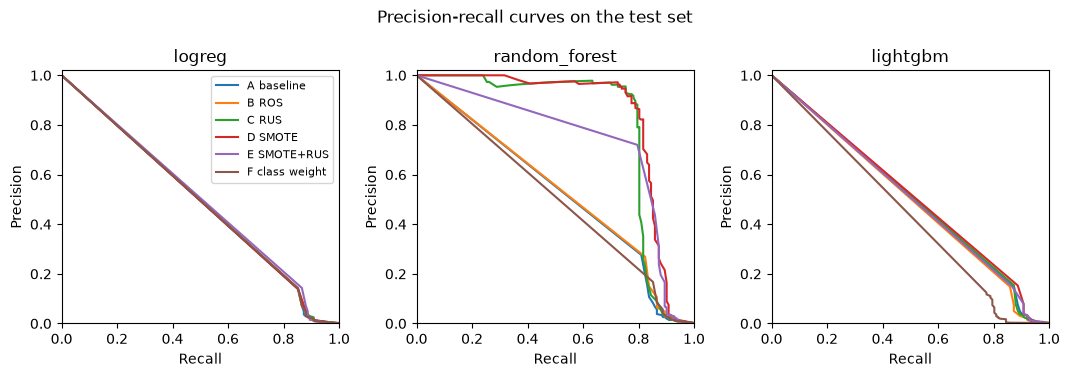

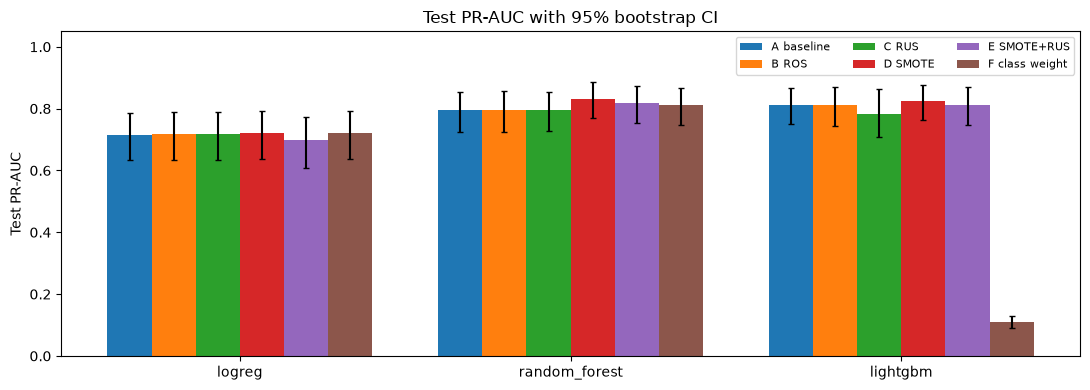

In [6]:
fig, axes = plt.subplots(1, len(models), figsize=(3.6 * len(models), 3.8), squeeze=False)
for ax, model in zip(axes[0], models, strict=True):
    for technique in TECHNIQUES:
        result = test_results.get(f"{model}__{technique}")
        if result:
            curve = result["pr_curve"]
            ax.plot(curve["recall"], curve["precision"], label=LABELS[technique])
    ax.set(title=model, xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02))
axes[0][0].legend(fontsize=8)
fig.suptitle("Precision-recall curves on the test set")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "pr_curves.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(11, 4))
width = 0.8 / len(TECHNIQUES)
for j, technique in enumerate(TECHNIQUES):
    for i, model in enumerate(models):
        result = test_results.get(f"{model}__{technique}")
        if result:
            value, (low, high) = result["test"]["pr_auc"], result["pr_auc_ci"]
            # (j - 2.5) * width spreads the 6 bars evenly around the model's tick at x = i
            ax.bar(i + (j - 2.5) * width, value, width, color=f"C{j}",
                   yerr=[[value - low], [high - value]], capsize=2,
                   label=LABELS[technique] if i == 0 else None)
ax.set_xticks(range(len(models)), models)
ax.set(ylabel="Test PR-AUC", ylim=(0, 1.05), title="Test PR-AUC with 95% bootstrap CI")
ax.legend(fontsize=8, ncol=3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "pr_auc_ci.png", dpi=150)
plt.show()

## 6. The headline cell in plain words
What the headline cell from section 3 would do with 100,000 payments at the fraud rate of
section 1, using its test recall (share of frauds caught) and false-positive rate (share of legit
payments flagged). The counts are rounded, so they are a picture of the rates, not exact
predictions.

In [7]:
payments = 100_000
test = test_results[headline]["test"]
expected_frauds = payments * fraud_rate
caught = expected_frauds * test["recall"]
false_alarms = (payments - expected_frauds) * test["fpr"]
print(f"headline cell: {headline}, at its F1 threshold {test_results[headline]['threshold_f1']:.3f}")
print(f"out of {payments:,} payments, about {expected_frauds:.0f} are frauds")
print(f"  caught:  {caught:.0f}")
print(f"  missed:  {expected_frauds - caught:.0f}")
print(f"  legit payments wrongly flagged: {false_alarms:.0f}")

headline cell: lightgbm__smote, at its F1 threshold 0.955
out of 100,000 payments, about 173 are frauds
  caught:  129
  missed:  44
  legit payments wrongly flagged: 4


## 7. Significance tests
For each model, each technique is compared with the baseline on the repeated-CV fold scores (every
cell was scored on exactly the same folds, so they can be paired fold by fold).

- **Wilcoxon signed-rank test**: takes the fold-by-fold differences (technique minus baseline)
  and asks whether they lean to one side more than chance would explain. `median_difference`
  above 0 means the technique scored higher than the baseline on a typical fold.
- **Holm correction**: each model has 5 comparisons, and the more tests you run, the more
  likely one looks significant by luck. Holm raises the p-values to allow for that (the smallest
  is multiplied by 5, the next by 4, and so on). `significant` uses the Holm p-value and 0.05.
- **Friedman test**: ranks the 6 techniques within every fold and asks whether any of them ranks
  consistently higher or lower, i.e. whether the techniques differ at all for that model.

Only the models that have cells are shown, even if `stats.json` is older and lists others.

The p-values are **approximate**: the folds share training rows, so the fold scores are not
independent, while these tests assume they are. Treat them as a guide, not as proof.

In [8]:
for model in models:  # only models with cells; stats.json may be older than the cells
    if model not in stats["models"]:
        print(f"{model}: no significance tests yet (run python -m fraudstudy.evaluation --stats)")
        continue
    result = stats["models"][model]
    table = pd.DataFrame(result["wilcoxon_vs_baseline"])
    table["technique"] = table["technique"].map(LABELS)
    table = table[["technique", "median_difference", "p_value", "p_value_holm", "significant"]]
    friedman_p = result["friedman"]["p_value"] if "friedman" in result else float("nan")
    print(f"{model}: Friedman p = {friedman_p:.3g}")
    display(table.round(4))

logreg: Friedman p = 0.0225


,technique,median_difference,p_value,p_value_holm,significant
0,B ROS,0.0021,0.0833,0.2498,False
1,C RUS,0.0027,0.1876,0.3752,False
2,D SMOTE,0.0093,0.0256,0.1023,False
3,E SMOTE+RUS,-0.0032,0.9780,0.9780,False
4,F class weight,0.0063,0.0084,0.0418,True


random_forest: Friedman p = 2.42e-07


,technique,median_difference,p_value,p_value_holm,significant
0,B ROS,-0.0015,0.3894,0.7788,False
1,C RUS,-0.0272,0.0001,0.0003,True
2,D SMOTE,0.0049,0.0256,0.1023,False
3,E SMOTE+RUS,-0.0027,0.2524,0.7571,False
4,F class weight,0.0000,0.9780,0.9780,False


lightgbm: Friedman p = 5.82e-10


,technique,median_difference,p_value,p_value_holm,significant
0,B ROS,0.0199,0.0002,0.0005,True
1,C RUS,-0.0017,0.8904,0.8904,False
2,D SMOTE,0.0191,0.0001,0.0005,True
3,E SMOTE+RUS,0.0110,0.0353,0.0707,False
4,F class weight,-0.1976,0.0001,0.0003,True


## 8. The README results table
The same numbers as Markdown text, to paste between the `RESULTS:START` and `RESULTS:END` marks
of `README.md`. CV PR-AUC is the training-only mean; the rest are test results at the cell's F1
threshold.

In [9]:
lines = ["| Model | Technique | CV PR-AUC | Test PR-AUC (95% CI) | Precision | Recall | F1 threshold |",
         "|---|---|---|---|---|---|---|"]
for model in models:
    for technique in TECHNIQUES:
        result = test_results.get(f"{model}__{technique}")
        if result is None:
            continue
        test, (low, high) = result["test"], result["pr_auc_ci"]
        lines.append(f"| {model} | {LABELS[technique]} | {result['cv_pr_auc_mean']:.4f} "
                     f"| {test['pr_auc']:.4f} ({low:.3f}-{high:.3f}) | {test['precision']:.3f} "
                     f"| {test['recall']:.3f} | {result['threshold_f1']:.3f} |")
print("\n".join(lines))

| Model | Technique | CV PR-AUC | Test PR-AUC (95% CI) | Precision | Recall | F1 threshold |
|---|---|---|---|---|---|---|
| logreg | A baseline | 0.7621 | 0.7149 (0.633-0.785) | 0.794 | 0.761 | 0.069 |
| logreg | B ROS | 0.7656 | 0.7179 (0.633-0.790) | 0.805 | 0.754 | 0.512 |
| logreg | C RUS | 0.7638 | 0.7191 (0.635-0.790) | 0.799 | 0.754 | 0.246 |
| logreg | D SMOTE | 0.7683 | 0.7214 (0.637-0.793) | 0.806 | 0.761 | 0.271 |
| logreg | E SMOTE+RUS | 0.7621 | 0.6971 (0.607-0.773) | 0.806 | 0.761 | 0.971 |
| logreg | F class weight | 0.7669 | 0.7214 (0.638-0.791) | 0.805 | 0.754 | 0.312 |
| random_forest | A baseline | 0.8471 | 0.7968 (0.726-0.855) | 0.947 | 0.761 | 0.470 |
| random_forest | B ROS | 0.8460 | 0.7946 (0.724-0.856) | 0.954 | 0.732 | 0.665 |
| random_forest | C RUS | 0.8180 | 0.7947 (0.727-0.854) | 0.882 | 0.789 | 0.510 |
| random_forest | D SMOTE | 0.8548 | 0.8324 (0.770-0.886) | 0.947 | 0.754 | 0.525 |
| random_forest | E SMOTE+RUS | 0.8406 | 0.8192 (0.755-0.874) | 0.915 

## 9. Conclusions

What we found, using the numbers from the sections above.

1. **The model matters more than the technique.** Logistic regression stays between 0.70 and
   0.72 test PR-AUC whatever we do to the data, while random forest and LightGBM reach 0.78 to
   0.83. Inside one model, the techniques move test PR-AUC by about 0.04 at most (leaving out
   LightGBM with class weighting, point 5).
2. **For LightGBM, oversampling helps a little.** Random oversampling (B) and SMOTE (D) both
   beat the baseline on the cross-validation folds by about 0.02 PR-AUC, and both stay
   significant after the Holm correction. SMOTE + undersampling (E) was also better (+0.011),
   but not significantly.
3. **For random forest and logistic regression, most techniques make no clear difference.**
   The only significant results are small: class weighting helped logistic regression by
   0.006, and random undersampling made random forest worse by 0.027, because it throws away
   most of the legit rows.
4. **SMOTE never hurt.** Its median difference from the baseline was positive for all three
   models (+0.009 logistic regression, +0.005 random forest, +0.019 LightGBM), although only
   the LightGBM one is significant.
5. **Class weighting can break a model.** LightGBM with class weighting (F) fell to 0.110 test
   PR-AUC. The search picked a fraud weight of 299.5, the model then gave 808 test payments the
   same top score of 1.0, and it could not rank them against each other (see the Results
   section of the README).
6. **The test set is too small to separate the good cells.** With 142 frauds in the test set,
   the 95% confidence intervals overlap a lot: the headline cell lightgbm__smote has 0.823
   (0.764-0.876) and the LightGBM baseline 0.813 (0.751-0.865). The differences we can trust
   come from the 15 cross-validation folds, not from one test score.
7. **Accuracy says nothing here.** Every cell is between 99.14% and 99.95% accurate, including
   LightGBM F, which wrongly flags 698 legit payments.

**Our answer to the research question:** no technique gave a big improvement over training on
the data as it is; the choice of model mattered much more. With LightGBM, oversampling
(random or SMOTE) gave a small but real gain. With random forest and logistic regression the
techniques made little difference, undersampling lost information, and class weighting has to
be tuned with care.

**Our pick:** lightgbm__smote had the best CV PR-AUC (0.864), so it is our headline cell. On
the test set it scores 0.823. Out of 100,000 payments it would catch about 129 of the 173
frauds, miss 44, and wrongly flag 4 legit payments. random_forest__smote had a slightly higher
test PR-AUC (0.832), but we choose on training data only, never on the test set.